# Prévision des Acquisitions LIN : Analyse & Scénarios SARIMAX

Ce notebook présente le modèle de prévision du volume quotidien total de vérifications (`t_verified_canal_sum`) basé sur un modèle **SARIMAX** intégrant les jours fériés, les week-ends et la disponibilité du service.

## 1. Chargement et Préparation des Données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import os
import warnings
warnings.filterwarnings("ignore")

# Chargement des données historiques
data_path = "../data/raw/Acquisition_LIN.csv" if os.path.exists("../data/raw/Acquisition_LIN.csv") else "data/raw/Acquisition_LIN.csv"
df_raw = pd.read_csv(data_path)
df_raw["date"] = pd.to_datetime(df_raw["date"])

# Filtrage : exclusion des données 2022 et sélection des canaux principaux
df = df_raw[df_raw["date"].dt.year > 2022].copy()
df = df[df["canal_verification"].isin(["digital", "bureau"])]

# Agrégation au niveau quotidien pour obtenir le volume total de vérifications
daily_total = df.groupby("date").agg({
    "t_verified_canal_sum": "sum",
    "ferie": "first",
    "week_end": "first",
    "Disponibilite_de_service": "first"
}).reset_index().sort_values("date")

# Imputation de sécurité sur la disponibilité de service
daily_total["Disponibilite_de_service"] = daily_total["Disponibilite_de_service"].fillna(0.0)

print(f"Données quotidiennes nettoyées : {daily_total.shape[0]} jours ({daily_total['date'].min().strftime('%Y-%m-%d')} à {daily_total['date'].max().strftime('%Y-%m-%d')})")
daily_total.head()

Données quotidiennes nettoyées : 1232 jours (2023-01-01 à 2026-06-23)


,date,t_verified_canal_sum,ferie,week_end,Disponibilite_de_service
0,2023-01-01,1194,1,1,0.0
1,2023-01-02,9618,0,0,0.0
2,2023-01-03,10258,0,0,0.0
3,2023-01-04,9880,0,0,0.0
4,2023-01-05,10725,0,0,0.0


## 2. Entraînement du Modèle SARIMAX

Entraînement du modèle SARIMAX `(1, 1, 1) x (1, 0, 1, 7)` avec les variables exogènes `ferie`, `week_end` et `Disponibilite_de_service` sur l'ensemble des observations historiques.

In [2]:
X = daily_total[["ferie", "week_end", "Disponibilite_de_service"]]
y = daily_total["t_verified_canal_sum"]

# Configuration et ajustement du modèle SARIMAX
model = sm.tsa.SARIMAX(
    y.values,
    exog=X.values,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)
res = model.fit(disp=False)
print(res.summary())

                                     SARIMAX Results                                     
Dep. Variable:                                 y   No. Observations:                 1232
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 7)   Log Likelihood              -10573.449
Date:                           Thu, 23 Jul 2026   AIC                          21162.898
Time:                                   17:21:56   BIC                          21203.764
Sample:                                        0   HQIC                         21178.278
                                          - 1232                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1         -4167.9491    182.659    -22.818      0.000   -4525.954   -3809.944
x2         -4546.8753    192.374    -23.636

## 3. Génération des Scénarios de Disponibilité (Future Période 2026)

Génération du calendrier futur jusqu'à la fin de l'année 2026 et simulation de deux scénarios comparatifs côte à côte :
* **Scénario A (`prediction_available`)** : Le service est toujours disponible (`Disponibilite_de_service = 0`).
* **Scénario B (`prediction_unavailable`)** : Le service est indisponible tous les jours (`Disponibilite_de_service = 1`).

In [ ]:
# Calendrier des jours fériés français en 2026
FERIE_2026 = [
    "2026-01-01", "2026-04-06", "2026-05-01", "2026-05-08",
    "2026-05-14", "2026-05-25", "2026-07-14", "2026-08-15",
    "2026-11-01", "2026-11-11", "2026-12-25"
]

# Date de fin du forecasting
END_DATE = "2026-12-31"

last_date = daily_total["date"].max()
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), end=END_DATE)

future_df = pd.DataFrame({"date": future_dates})
future_df["day_of_week"] = future_df["date"].dt.dayofweek
future_df["week_end"] = future_df["day_of_week"].apply(lambda x: 1 if x >= 5 else 0)
future_df["ferie"] = future_df["date"].dt.strftime("%Y-%m-%d").isin(FERIE_2026).astype(int)

# Scénario A : Service toujours disponible (Disponibilite_de_service = 0)
exog_A = future_df[["ferie", "week_end"]].copy()
exog_A["Disponibilite_de_service"] = 0.0
pred_A = np.maximum(0, res.forecast(steps=len(future_df), exog=exog_A.values))

# Scénario B : Service indisponible tous les jours (Disponibilite_de_service = 1)
exog_B = future_df[["ferie", "week_end"]].copy()
exog_B["Disponibilite_de_service"] = 1.0
pred_B = np.maximum(0, res.forecast(steps=len(future_df), exog=exog_B.values))

# Création du DataFrame comparatif côte à côte
scenarios_df = pd.DataFrame({
    "date": future_df["date"].dt.strftime("%Y-%m-%d"),
    "ferie": future_df["ferie"],
    "week_end": future_df["week_end"],
    "prediction_available": pred_A,
    "prediction_unavailable": pred_B
})

# Export du fichier CSV final
output_csv = "../data/processed/Forecast_Scenarios.csv" if os.path.exists("../data/processed") else "data/processed/Forecast_Scenarios.csv"
scenarios_df.to_csv(output_csv, index=False)
print(f"Fichier des scénarios exporté vers {output_csv}")
scenarios_df.head(10)

Fichier des scénarios exporté vers ../data/processed/Forecast_Scenarios.csv


,date,ferie,week_end,prediction_available,prediction_unavailable
0,2026-06-24,0,0,5427.471976,4859.171708
1,2026-06-25,0,0,5421.342237,4853.041970
2,2026-06-26,0,0,4961.489202,4393.188935
3,2026-06-27,0,1,1954.590446,1386.290179
4,2026-06-28,0,1,1188.471958,620.171690
5,2026-06-29,0,0,4992.659056,4424.358789
6,2026-06-30,0,0,5571.922125,5003.621858
7,2026-07-01,0,0,5345.980425,4777.680158
8,2026-07-02,0,0,5326.015918,4757.715650
9,2026-07-03,0,0,4878.565112,4310.264844


## 4. Visualisation Graphique des Prévisions

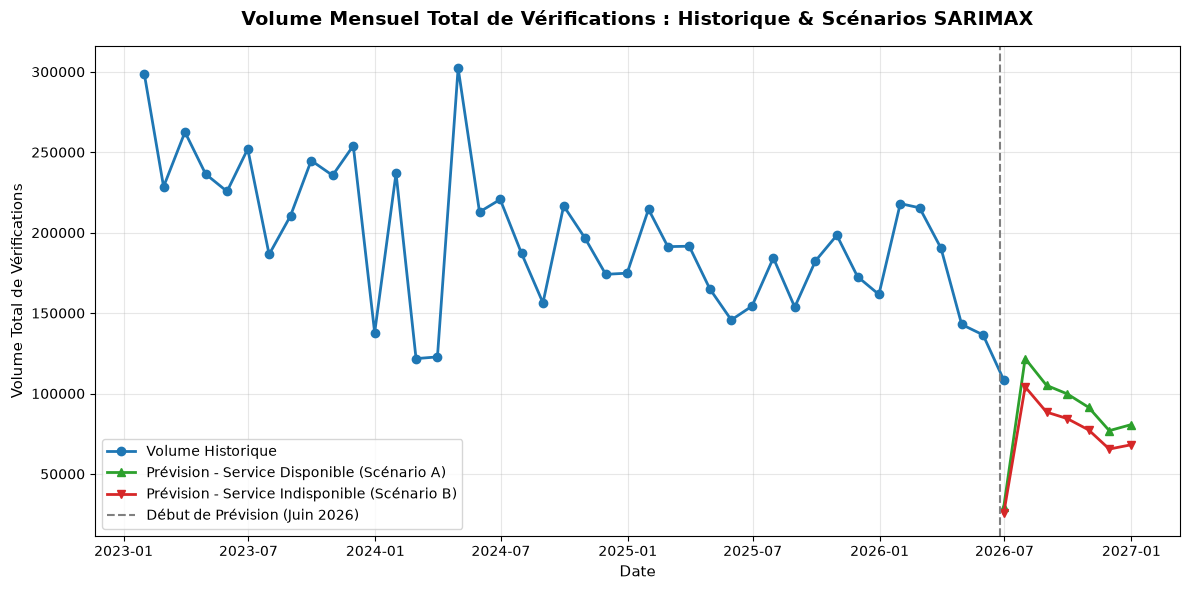

In [4]:
# Agrégation mensuelle pour une vue synthétique et managériale
monthly_hist = daily_total.set_index("date").resample("ME")["t_verified_canal_sum"].sum()

scenarios_df["date_dt"] = pd.to_datetime(scenarios_df["date"])
monthly_fcst = scenarios_df.set_index("date_dt").resample("ME")[["prediction_available", "prediction_unavailable"]].sum()

plt.figure(figsize=(12, 6))
plt.plot(monthly_hist.index, monthly_hist.values, label="Volume Historique", marker="o", color="#1f77b4", linewidth=2)
plt.plot(monthly_fcst.index, monthly_fcst["prediction_available"], label="Prévision - Service Disponible (Scénario A)", marker="^", color="#2ca02c", linewidth=2)
plt.plot(monthly_fcst.index, monthly_fcst["prediction_unavailable"], label="Prévision - Service Indisponible (Scénario B)", marker="v", color="#d62728", linewidth=2)

plt.axvline(x=pd.to_datetime("2026-06-24"), color="gray", linestyle="--", label="Début de Prévision (Juin 2026)")
plt.title("Volume Mensuel Total de Vérifications : Historique & Scénarios SARIMAX", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Date", fontsize=11)
plt.ylabel("Volume Total de Vérifications", fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()